# Task 3 — Midterm Project: Bank Marketing
Student: Smakov Danieldiaz · SEED: 3194 (last 4 digits of student ID)

In [1]:
import re
import sys
from importlib.metadata import version, PackageNotFoundError

import numpy as np
import pandas as pd

SEED = 3194

print("Python:", sys.version.split()[0])
with open("requirements.txt") as f:
    for line in f:
        name = re.split(r"[=<>!~\[; ]", line.strip())[0]
        if name and not name.startswith("#"):
            try:
                print(f"  {name:20s} {version(name)}")
            except PackageNotFoundError:
                print(f"  {name:20s} NOT INSTALLED")

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

print("\ntrain:", train.shape, "| test:", test.shape)
print("Only in train:", sorted(set(train.columns) - set(test.columns)))
print("Only in test :", sorted(set(test.columns) - set(train.columns)))
print("\nTrain columns:", list(train.columns))

Python: 3.12.5
  numpy                2.3.4
  scipy                1.16.3
  pandas               2.3.3
  matplotlib           3.10.7
  scikit-learn         1.7.2
  joblib               1.5.2

train: (32940, 22) | test: (8236, 20)
Only in train: ['duration', 'y']
Only in test : []

Train columns: ['id', 'age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']


In [2]:
train.head()

,id,age,job,marital,education,default,housing,loan,contact,month,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,0,39,management,single,basic.9y,unknown,yes,no,telephone,may,...,3,999,0,nonexistent,1.1,93.994,-36.4,4.856,5191.0,no
1,1,32,admin.,single,university.degree,no,yes,no,cellular,aug,...,2,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,no
2,2,41,technician,married,high.school,no,no,yes,cellular,aug,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,no
3,3,39,admin.,married,professional.course,no,yes,yes,telephone,may,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,4,51,blue-collar,married,basic.9y,unknown,no,no,telephone,jun,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.864,5228.1,no


## Stage 1. Framing

The bank calls clients to sell a term deposit. For each client I need to predict how likely they are to say yes, and this has to happen before the call is made.

The call centre can only call 10% of the list. So in practice the model is used to rank clients: sort them by score and call the top 10%. Because of that, accuracy and the usual 0.5 threshold don't really matter here. What matters is how many "yes" clients end up in that top 10%.

To compare models I use average precision (area under the precision-recall curve) as the main metric. The data is imbalanced, only about 11% say yes, and AP pays more attention to the top of the ranking than ROC-AUC does. I also report ROC-AUC, since the hidden test set is scored with it. At the end I check precision, recall and lift for the top 10% on my hold-out.

The train and test files don't have the same columns. test.csv has no y, which is expected, but it also has no duration. Duration is how long the call lasted, so it's only known after the call is over. It's strongly linked to the answer (a short call almost always means no), but we score clients before calling them, so we won't have it at prediction time. If I used it, the model would look great in validation but be useless in reality. This is data leakage, so I drop duration. I also drop id, because it's just a row number.

## Stage 2 · Understanding the data

In [3]:
y_all = (train["y"] == "yes").astype(int)

print(train["y"].value_counts())
print(f"\nShare of 'yes': {y_all.mean():.4f}")
print(f"Accuracy of always predicting 'no': {1 - y_all.mean():.4f}")

y
no     29229
yes     3711
Name: count, dtype: int64

Share of 'yes': 0.1127
Accuracy of always predicting 'no': 0.8873


In [4]:
print("Real NaN in train:", train.isna().sum().sum(), "| in test:", test.isna().sum().sum())

cat_cols = [c for c in train.select_dtypes("object").columns if c != "y"]
num_cols = [c for c in train.columns if c not in cat_cols + ["id", "y", "duration"]]
print("\nCategorical:", cat_cols)
print("Numeric    :", num_cols)

unknown = pd.DataFrame({
    "train_count": (train[cat_cols] == "unknown").sum(),
    "train_share": (train[cat_cols] == "unknown").mean().round(4),
    "test_count":  (test[cat_cols] == "unknown").sum(),
})
print("\n'unknown' per categorical column:")
print(unknown[unknown["train_count"] > 0])

n999 = (train["pdays"] == 999).sum()
print(f"\npdays == 999: {n999} rows ({n999 / len(train):.4f} of train)")
print("\npdays==999 vs poutcome:")
print(pd.crosstab(train["pdays"] == 999, train["poutcome"]))
print("\npdays==999 vs previous == 0:")
print(pd.crosstab(train["pdays"] == 999, train["previous"] == 0))

print("\ndefault value counts:")
print(train["default"].value_counts())

Real NaN in train: 0 | in test: 0

Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Numeric    : ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

'unknown' per categorical column:
           train_count  train_share  test_count
job                275       0.0083          55
marital             64       0.0019          16
education         1401       0.0425         329
default           6871       0.2086        1725
housing            794       0.0241         196
loan               794       0.0241         196

pdays == 999: 31694 rows (0.9622 of train)

pdays==999 vs poutcome:
poutcome  failure  nonexistent  success
pdays                                  
False         116            0     1130
True         3248        28446        0

pdays==999 vs previous == 0:
previous  False  True 
pdays                 
False      1246      0
True       

In [5]:
from scipy.stats import spearmanr

print("First 20 months by id:", train.sort_values("id")["month"].head(20).tolist())
for col in ["euribor3m", "nr.employed", "emp.var.rate"]:
    rho, _ = spearmanr(train["id"], train[col])
    print(f"Spearman(id, {col}) = {rho:+.3f}")

First 20 months by id: ['may', 'aug', 'aug', 'may', 'jun', 'aug', 'may', 'apr', 'jul', 'nov', 'nov', 'sep', 'aug', 'jul', 'aug', 'nov', 'may', 'apr', 'jun', 'jun']
Spearman(id, euribor3m) = -0.002
Spearman(id, nr.employed) = -0.002
Spearman(id, emp.var.rate) = -0.001


In [6]:
print("poutcome vs previous == 0:")
print(pd.crosstab(train["poutcome"], train["previous"] == 0))

both = ((train["housing"] == "unknown") & (train["loan"] == "unknown")).sum()
print(f"\nhousing and loan both 'unknown': {both} rows")

print("\nShare of 'yes' by category (does 'unknown' behave differently?):")
for col in ["default", "education", "job"]:
    t = y_all.groupby(train[col]).agg(yes_rate="mean", count="count").round(3)
    print(f"\n{col}:\n{t}")

poutcome vs previous == 0:
previous     False  True 
poutcome                 
failure       3364      0
nonexistent      0  28446
success       1130      0

housing and loan both 'unknown': 794 rows

Share of 'yes' by category (does 'unknown' behave differently?):

default:
         yes_rate  count
default                 
no          0.129  26067
unknown     0.052   6871
yes         0.000      2

education:
                     yes_rate  count
education                           
basic.4y                0.101   3372
basic.6y                0.083   1800
basic.9y                0.077   4855
high.school             0.109   7591
illiterate              0.286     14
professional.course     0.116   4155
university.degree       0.137   9752
unknown                 0.144   1401

job:
               yes_rate  count
job                           
admin.            0.131   8398
blue-collar       0.070   7393
entrepreneur      0.085   1185
housemaid         0.098    861
management        0.114  

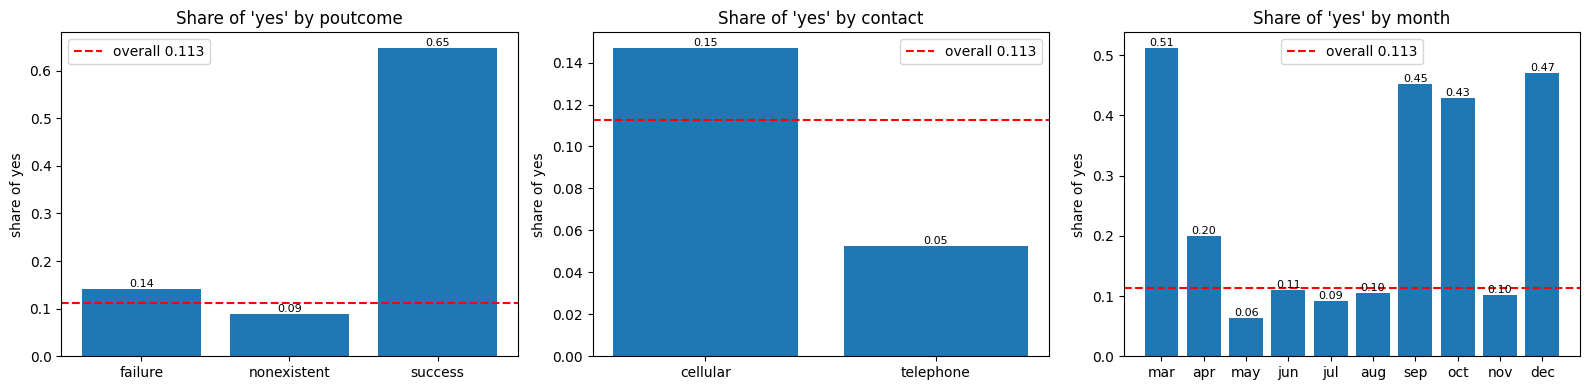


poutcome:
             yes_rate  count
poutcome                    
failure         0.140   3364
nonexistent     0.088  28446
success         0.648   1130

contact:
           yes_rate  count
contact                   
cellular      0.147  20946
telephone     0.053  11994

month:
       yes_rate  count
month                 
apr       0.200   2089
aug       0.104   4937
dec       0.469    147
jul       0.091   5820
jun       0.110   4249
mar       0.512    457
may       0.064  10942
nov       0.103   3287
oct       0.429    559
sep       0.453    453


In [7]:
import matplotlib.pyplot as plt

month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["poutcome", "contact", "month"]):
    t = y_all.groupby(train[col]).agg(yes_rate="mean", count="count")
    if col == "month":
        t = t.reindex(month_order)
    bars = ax.bar(t.index, t["yes_rate"])
    ax.bar_label(bars, labels=[f"{v:.2f}" for v in t["yes_rate"]], fontsize=8)
    ax.axhline(y_all.mean(), color="red", linestyle="--", label=f"overall {y_all.mean():.3f}")
    ax.set_title(f"Share of 'yes' by {col}")
    ax.set_ylabel("share of yes")
    ax.legend()
plt.tight_layout()
plt.show()

for col in ["poutcome", "contact", "month"]:
    t = y_all.groupby(train[col]).agg(yes_rate="mean", count="count").round(3)
    print(f"\n{col}:\n{t}")

Single-feature ROC-AUC (strength = max(auc, 1-auc)):
       feature   auc  strength
   nr.employed 0.250     0.750
     euribor3m 0.255     0.745
  emp.var.rate 0.283     0.717
      previous 0.610     0.610
cons.price.idx 0.391     0.609
         pdays 0.401     0.599
      campaign 0.447     0.553
 cons.conf.idx 0.542     0.542
           age 0.491     0.509


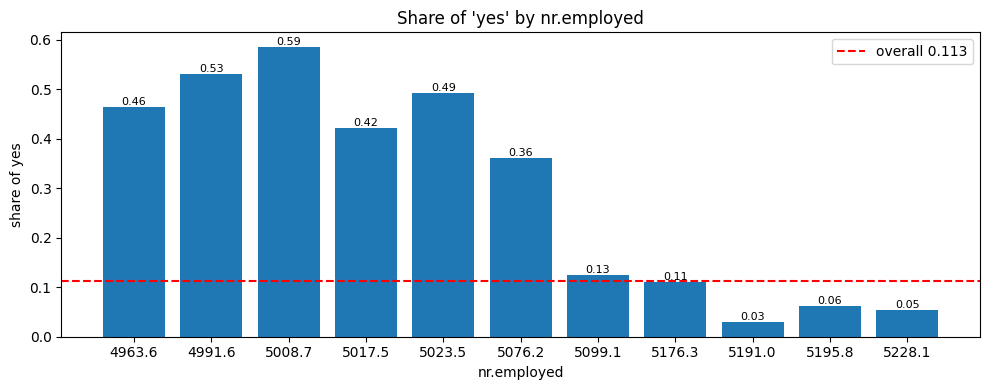

             yes_rate  count
nr.employed                 
4963.6          0.463    512
4991.6          0.530    619
5008.7          0.585    528
5017.5          0.421    862
5023.5          0.493    138
5076.2          0.360   1349
5099.1          0.125   6786
5176.3          0.111      9
5191.0          0.030   6174
5195.8          0.062   2925
5228.1          0.054  13038


In [8]:
from sklearn.metrics import roc_auc_score

rows = []
for col in num_cols:
    auc = roc_auc_score(y_all, train[col])
    rows.append({"feature": col, "auc": round(auc, 3), "strength": round(max(auc, 1 - auc), 3)})
num_strength = pd.DataFrame(rows).sort_values("strength", ascending=False)
print("Single-feature ROC-AUC (strength = max(auc, 1-auc)):")
print(num_strength.to_string(index=False))

t = y_all.groupby(train["nr.employed"]).agg(yes_rate="mean", count="count")
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(t.index.astype(str), t["yes_rate"])
ax.bar_label(bars, labels=[f"{v:.2f}" for v in t["yes_rate"]], fontsize=8)
ax.axhline(y_all.mean(), color="red", linestyle="--", label=f"overall {y_all.mean():.3f}")
ax.set_title("Share of 'yes' by nr.employed")
ax.set_xlabel("nr.employed")
ax.set_ylabel("share of yes")
ax.legend()
plt.tight_layout()
plt.show()
print(t.round(3))

### What I found so far

Class balance. Only 3711 of 32940 clients said yes (11.3%). A model that always says "no" already gets 88.7% accuracy, so accuracy tells almost nothing on this data.

Missing values. There are no real NaN values, missing values are written as "unknown" instead. Counts in train: default 6871 (20.9%), education 1401 (4.3%), housing 794, loan 794, job 275, marital 64. Housing and loan are unknown in exactly the same 794 rows, so it's probably one missing source. For default, "unknown" doesn't look random: these clients say yes only 5.2% of the time, compared to 12.9% for "no". Also default = "yes" appears only 2 times, so this column is basically "no" vs "unknown". Because of this I don't want to just fill "unknown" with the most common value. I keep it as its own category and check this choice with CV later.

Sentinel. pdays = 999 is not a real number of days, it means "no previous contact recorded". It's in 31694 rows (96.2%). If I leave it as a number, 999 looks like a huge value, which messes up scaling and distance-based models like KNN and SVM. One thing I noticed: 999 doesn't exactly mean "never contacted". poutcome = nonexistent matches previous = 0 exactly (28446 rows), but there are also 3248 rows with pdays = 999 and poutcome = failure. These clients were contacted before, pdays just wasn't recorded for them. So I handle pdays separately: replace 999 with a normal value and add a 0/1 flag column for it.

Row order. The original UCI file is sorted by date, but here the rows are shuffled: the Spearman correlation between id and euribor3m, nr.employed, emp.var.rate is about 0 (-0.002). So the row order has no meaning and a normal stratified random split is fine. But there is no year column, and month plus the economic indicators basically tell which period the call was made in. I come back to this in Stage 7.

### Which features are related to the answer

poutcome is the strongest category. Clients for whom the previous campaign was a success say yes 64.8% of the time (1130 clients), compared to 11.3% overall and 8.8% for clients who were never contacted before.

contact: cellular 14.7% yes vs telephone 5.3%, almost 3 times more.

month: May had the most calls (10942) and the lowest yes rate (6.4%). In March, September, October and December the yes rate is 43-51%, but there were few calls in those months (147-559). This looks more like a difference between time periods than something about the month itself.

For numeric features I computed the ROC-AUC of each feature on its own. The strongest are the economic indicators: nr.employed 0.75, euribor3m 0.745, emp.var.rate 0.717 (their AUC is below 0.5, which means lower values go with more yes). On the plot, when nr.employed is 5076 or lower the yes rate is 36-59%, and when it's 5191 or higher it's only 3-6%. Next come previous (0.61) and pdays (0.60). campaign is weak (0.553): more calls in this campaign means a bit fewer yes. age is almost 0.5 (0.509), but this AUC only catches a "more = better" type of relation, and age can matter in a non-linear way (for example job = student has 30.5% yes).

The economic indicators are known before the call, so I can use them. But they describe the general situation in a period, not the client. If the economy changes, the model may work worse than it does here.

## Stage 3. Validation design

First I put aside 20% of train.csv as my own hold-out (6588 rows), stratified by y and with my SEED. I don't touch it until Stage 7. All comparisons and tuning happen on the other 80% (the dev part, 26352 rows) with cross-validation.

Splitter: StratifiedKFold with 5 folds, shuffle=True, random_state=SEED. I use stratified folds because only 11% of clients are yes, and I want every fold to have about the same share of yes. Otherwise the scores could jump between folds just because of how many yes ended up in each one. I don't use a time-based split because the rows are shuffled and there is no date column to sort by. The same cv object is used for every model, so all models are compared on exactly the same folds.

In [9]:
from sklearn.model_selection import train_test_split, StratifiedKFold

y = (train["y"] == "yes").astype(int)
X = train.drop(columns=["id", "y", "duration"])

X_dev, X_hold, y_dev, y_hold = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

print("dev :", X_dev.shape, f"| yes share {y_dev.mean():.4f}")
print("hold:", X_hold.shape, f"| yes share {y_hold.mean():.4f}")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print()
for i, (tr_idx, va_idx) in enumerate(cv.split(X_dev, y_dev), 1):
    print(f"fold {i}: train {len(tr_idx)}, valid {len(va_idx)}, "
          f"yes share in valid {y_dev.iloc[va_idx].mean():.4f}")

scoring = {"ap": "average_precision", "roc_auc": "roc_auc"}

dev : (26352, 19) | yes share 0.1127
hold: (6588, 19) | yes share 0.1126

fold 1: train 21081, valid 5271, yes share in valid 0.1127
fold 2: train 21081, valid 5271, yes share in valid 0.1127
fold 3: train 21082, valid 5270, yes share in valid 0.1125
fold 4: train 21082, valid 5270, yes share in valid 0.1127
fold 5: train 21082, valid 5270, yes share in valid 0.1127


## Stage 4. Preprocessing

All preprocessing is inside one sklearn Pipeline together with the model. When cross_validate fits the pipeline on a fold, the encoder, imputer and scaler only see the training rows of that fold, and the validation rows are only transformed. The final model works the same way: it's fitted on train and then just applied to test.csv. I check this below by looking inside the fitted pipeline for each fold.

Categorical columns (job, marital, education, default, housing, loan, contact, month, day_of_week, poutcome) are one-hot encoded. "unknown" stays as its own category, because at least for default it clearly behaves differently (5.2% yes vs 12.9% for "no"). I use handle_unknown="ignore" so the pipeline doesn't crash if test.csv has a value it hasn't seen.

For pdays, 999 is treated as missing. SimpleImputer replaces it with the median of the real values and adds a 0/1 column that says "pdays was 999". After that it's scaled.

The other numeric columns go through StandardScaler. Trees don't need scaling, but logistic regression, KNN and SVM do, and this way every model uses the same pipeline.

id and duration are not used: ColumnTransformer drops every column that isn't listed, so the pipeline can take the raw test.csv columns directly.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

cat_cols = ["job", "marital", "education", "default", "housing", "loan",
            "contact", "month", "day_of_week", "poutcome"]
num_plain = ["age", "campaign", "previous", "emp.var.rate", "cons.price.idx",
             "cons.conf.idx", "euribor3m", "nr.employed"]

def make_preprocess():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("pdays", Pipeline([
            ("fix999", SimpleImputer(missing_values=999, strategy="median", add_indicator=True)),
            ("scale", StandardScaler()),
        ]), ["pdays"]),
        ("num", StandardScaler(), num_plain),
    ], remainder="drop")

prep_check = make_preprocess().fit(X_dev)
print("Number of features after preprocessing:", len(prep_check.get_feature_names_out()))

Number of features after preprocessing: 63


## Stage 5. Baselines

Two baselines on the same 5 folds: a majority-class model that always says "no", and a plain logistic regression with default settings. Every model later has to beat them.

In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

scoring_all = {"ap": "average_precision", "roc_auc": "roc_auc", "accuracy": "accuracy"}
cv_results = {}

def run_cv(name, model, return_estimator=False):
    pipe = Pipeline([("prep", make_preprocess()), ("model", model)])
    res = cross_validate(pipe, X_dev, y_dev, cv=cv, scoring=scoring_all,
                         return_estimator=return_estimator, n_jobs=-1)
    cv_results[name] = res
    return res

def summary():
    rows = []
    for name, res in cv_results.items():
        row = {"model": name}
        for m in scoring_all:
            row[f"{m}_mean"] = res[f"test_{m}"].mean()
            row[f"{m}_std"] = res[f"test_{m}"].std()
        rows.append(row)
    return pd.DataFrame(rows).set_index("model").round(4)

run_cv("majority (always no)", DummyClassifier(strategy="most_frequent"))
run_cv("logreg default", LogisticRegression(max_iter=1000), return_estimator=True)

print(summary().to_string())
for name, res in cv_results.items():
    print(f"\n{name}")
    print("  AP per fold     :", np.round(res["test_ap"], 4))
    print("  ROC-AUC per fold:", np.round(res["test_roc_auc"], 4))

                      ap_mean  ap_std  roc_auc_mean  roc_auc_std  accuracy_mean  accuracy_std
model                                                                                        
majority (always no)   0.1127  0.0001        0.5000        0.000         0.8873        0.0001
logreg default         0.4579  0.0109        0.7936        0.004         0.9000        0.0018

majority (always no)
  AP per fold     : [0.1127 0.1127 0.1125 0.1127 0.1127]
  ROC-AUC per fold: [0.5 0.5 0.5 0.5 0.5]

logreg default
  AP per fold     : [0.4493 0.4738 0.4536 0.4674 0.4454]
  ROC-AUC per fold: [0.7936 0.7866 0.7926 0.7969 0.7981]


In [12]:
dev_age_mean = X_dev["age"].mean()
dev_pdays_median = X_dev.loc[X_dev["pdays"] != 999, "pdays"].median()
print(f"Whole dev part: {len(X_dev)} rows, age mean {dev_age_mean:.4f}, "
      f"pdays median (without 999) {dev_pdays_median}\n")

for i, est in enumerate(cv_results["logreg default"]["estimator"], 1):
    prep = est.named_steps["prep"]
    scaler = prep.named_transformers_["num"]
    imputer = prep.named_transformers_["pdays"].named_steps["fix999"]
    print(f"fold {i}: scaler fitted on {scaler.n_samples_seen_} rows, "
          f"age mean {scaler.mean_[0]:.4f}, pdays median {imputer.statistics_[0]}")

Whole dev part: 26352 rows, age mean 40.0505, pdays median (without 999) 6.0

fold 1: scaler fitted on 21081 rows, age mean 40.0755, pdays median 6.0
fold 2: scaler fitted on 21081 rows, age mean 40.1038, pdays median 6.0
fold 3: scaler fitted on 21082 rows, age mean 40.0273, pdays median 6.0
fold 4: scaler fitted on 21082 rows, age mean 39.9981, pdays median 6.0
fold 5: scaler fitted on 21082 rows, age mean 40.0479, pdays median 6.0


### Baseline results

The majority model gets 88.7% accuracy, but its AP is 0.113 (just the share of yes) and its ROC-AUC is 0.5, so it can't rank anyone. Logistic regression gets AP 0.458 ± 0.011 and ROC-AUC 0.794 ± 0.004, but its accuracy is only 90.0%, just 1.3 points more than always saying no. So accuracy hides almost all of the difference between a useless model and a useful one, and I don't use it to choose models.

These numbers are the bar for every later model: AP above 0.458 and ROC-AUC above 0.794.

Fold spread. For logistic regression, AP goes from 0.445 to 0.474 between folds (std 0.011), and ROC-AUC from 0.787 to 0.798 (std 0.004). So if two models differ by less than about 0.01 in AP or 0.004 in ROC-AUC, that difference can come just from how the data was split, and I won't call one of them better. Since all models use the same folds, I can also compare them fold by fold: a real improvement should show up in most folds, not only in the average.

In every fold the scaler was fitted on 21081-21082 rows, not on all 26352 rows of the dev part, and the mean age it learned is slightly different each time (39.998 to 40.104, compared to 40.051 on the whole dev part). So the preprocessing in each fold only learned from that fold's training rows, and the validation rows had no influence on it. The pdays median is 6 in every fold, so the value used to replace 999 is stable.

In [13]:
def make_preprocess_variant(unknown="category", pdays="flag"):
    if unknown == "category":
        cat_step = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    else:
        cat_step = Pipeline([
            ("fill", SimpleImputer(missing_values="unknown", strategy="most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ])
    if pdays == "flag":
        pdays_step = Pipeline([
            ("fix999", SimpleImputer(missing_values=999, strategy="median", add_indicator=True)),
            ("scale", StandardScaler()),
        ])
    else:
        pdays_step = StandardScaler()
    return ColumnTransformer([
        ("cat", cat_step, cat_cols),
        ("pdays", pdays_step, ["pdays"]),
        ("num", StandardScaler(), num_plain),
    ], remainder="drop")

variants = {
    "my choice: unknown=category, pdays=flag": dict(unknown="category", pdays="flag"),
    "unknown -> most frequent": dict(unknown="mode", pdays="flag"),
    "pdays raw (999 kept)": dict(unknown="category", pdays="raw"),
}

rows, fold_ap = [], {}
for name, kw in variants.items():
    pipe = Pipeline([("prep", make_preprocess_variant(**kw)),
                     ("model", LogisticRegression(max_iter=1000))])
    res = cross_validate(pipe, X_dev, y_dev, cv=cv, scoring=scoring, n_jobs=-1)
    fold_ap[name] = res["test_ap"]
    rows.append({"variant": name,
                 "ap_mean": res["test_ap"].mean(), "ap_std": res["test_ap"].std(),
                 "roc_auc_mean": res["test_roc_auc"].mean(), "roc_auc_std": res["test_roc_auc"].std()})

print(pd.DataFrame(rows).set_index("variant").round(4).to_string())

base_name = list(variants)[0]
print()
for name in list(variants)[1:]:
    diff = fold_ap[base_name] - fold_ap[name]
    print(f"my choice minus '{name}': AP diff per fold {np.round(diff, 4)}, "
          f"mean {diff.mean():+.4f}, my choice better in {(diff > 0).sum()}/5 folds")

                                         ap_mean  ap_std  roc_auc_mean  roc_auc_std
variant                                                                            
my choice: unknown=category, pdays=flag   0.4579  0.0109        0.7936       0.0040
unknown -> most frequent                  0.4578  0.0114        0.7931       0.0037
pdays raw (999 kept)                      0.4577  0.0105        0.7934       0.0040

my choice minus 'unknown -> most frequent': AP diff per fold [ 0.0009  0.0007 -0.0011 -0.0015  0.0015], mean +0.0001, my choice better in 3/5 folds
my choice minus 'pdays raw (999 kept)': AP diff per fold [-0.0009  0.0001  0.0001  0.0016  0.    ], mean +0.0002, my choice better in 4/5 folds


### Does the preprocessing choice matter?

I compared my preprocessing with two alternatives using logistic regression on the same folds. Replacing "unknown" with the most frequent value gives AP 0.4578 vs 0.4579 for my version, and keeping pdays = 999 as a raw number gives 0.4577. The differences are 0.0001-0.0002, while the fold std is about 0.011, so all three are the same within noise.

For pdays it makes sense: after scaling, 96% of the rows sit at one value, so the raw column basically works as a "was 999 or not" flag anyway, and the same information is also in previous and poutcome. I still keep my version. Keeping "unknown" as a category doesn't throw away information (for default it has a very different yes rate), and the explicit flag for 999 is safer for KNN and SVM, which work with distances and would see 999 as a huge real value.

## Stage 6. Comparing models and tuning

I compare five model families from the course: logistic regression, linear SVM, KNN, decision tree and random forest. Each one goes into the same pipeline (same preprocessing) and is tuned with GridSearchCV on the same 5 folds of the dev part, using AP as the score to pick the best settings. The hold-out is not used here.

Search spaces:
- Logistic regression: C in [0.01, 0.1, 1, 10], class_weight in [None, balanced]
- Linear SVM: C in [0.01, 0.1, 1], class_weight in [None, balanced]
- KNN: n_neighbors in [25, 50, 100, 200], weights in [uniform, distance]
- Decision tree: max_depth in [3, 5, 7, 10, None], min_samples_leaf in [1, 20, 50, 100], class_weight in [None, balanced]
- Random forest (300 trees): min_samples_leaf in [10, 20, 50], max_features in [sqrt, 0.3], class_weight in [None, balanced_subsample]

class_weight is in the grid so that I can compare handling the imbalance vs doing nothing on the same folds. KNN has no class_weight option. For the random forest I don't try min_samples_leaf = 1, because fully grown trees would make the saved model much bigger than the 50 MB limit.

The best CV score after tuning is a bit optimistic, because the same folds were used to pick the settings. That's one of the reasons for the separate hold-out in Stage 7.

In [14]:
import time
from sklearn.model_selection import GridSearchCV
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

searches = {}

def tune(name, model, grid):
    pipe = Pipeline([("prep", make_preprocess()), ("model", model)])
    gs = GridSearchCV(pipe, {f"model__{k}": v for k, v in grid.items()},
                      scoring=scoring, refit="ap", cv=cv, n_jobs=-1)
    t0 = time.time()
    gs.fit(X_dev, y_dev)
    searches[name] = gs
    i = gs.best_index_
    print(f"{name}: {time.time() - t0:.0f}s")
    print(f"  best params: {gs.best_params_}")
    print(f"  AP {gs.cv_results_['mean_test_ap'][i]:.4f} ± {gs.cv_results_['std_test_ap'][i]:.4f} | "
          f"ROC-AUC {gs.cv_results_['mean_test_roc_auc'][i]:.4f} ± {gs.cv_results_['std_test_roc_auc'][i]:.4f}")
    return gs

def fold_scores(gs, idx, metric):
    return np.array([gs.cv_results_[f"split{k}_test_{metric}"][idx] for k in range(cv.get_n_splits())])

In [15]:
tune("logreg", LogisticRegression(max_iter=2000),
     {"C": [0.01, 0.1, 1, 10], "class_weight": [None, "balanced"]})

tune("linear SVM", LinearSVC(max_iter=5000, random_state=SEED),
     {"C": [0.01, 0.1, 1], "class_weight": [None, "balanced"]});

logreg: 1s
  best params: {'model__C': 1, 'model__class_weight': None}
  AP 0.4579 ± 0.0109 | ROC-AUC 0.7936 ± 0.0040
linear SVM: 1s
  best params: {'model__C': 0.1, 'model__class_weight': None}
  AP 0.4548 ± 0.0134 | ROC-AUC 0.7900 ± 0.0038


In [16]:
tune("KNN", KNeighborsClassifier(),
     {"n_neighbors": [25, 50, 100, 200], "weights": ["uniform", "distance"]});

KNN: 3s
  best params: {'model__n_neighbors': 200, 'model__weights': 'uniform'}
  AP 0.4418 ± 0.0115 | ROC-AUC 0.7930 ± 0.0076


In [17]:
tune("decision tree", DecisionTreeClassifier(random_state=SEED),
     {"max_depth": [3, 5, 7, 10, None], "min_samples_leaf": [1, 20, 50, 100],
      "class_weight": [None, "balanced"]});

decision tree: 5s
  best params: {'model__class_weight': None, 'model__max_depth': None, 'model__min_samples_leaf': 100}
  AP 0.4531 ± 0.0101 | ROC-AUC 0.7887 ± 0.0092


In [18]:
tune("random forest", RandomForestClassifier(n_estimators=300, random_state=SEED),
     {"min_samples_leaf": [10, 20, 50], "max_features": ["sqrt", 0.3],
      "class_weight": [None, "balanced_subsample"]});

random forest: 45s
  best params: {'model__class_weight': None, 'model__max_features': 0.3, 'model__min_samples_leaf': 10}
  AP 0.4820 ± 0.0117 | ROC-AUC 0.8023 ± 0.0045


In [19]:
rows, best_ap_folds = [], {}
for name in ["majority (always no)", "logreg default"]:
    res = cv_results[name]
    best_ap_folds[name] = res["test_ap"]
    rows.append({"model": name,
                 "ap_mean": res["test_ap"].mean(), "ap_std": res["test_ap"].std(),
                 "roc_auc_mean": res["test_roc_auc"].mean(), "roc_auc_std": res["test_roc_auc"].std()})
for name, gs in searches.items():
    i = gs.best_index_
    ap, auc = fold_scores(gs, i, "ap"), fold_scores(gs, i, "roc_auc")
    best_ap_folds[name] = ap
    rows.append({"model": name, "ap_mean": ap.mean(), "ap_std": ap.std(),
                 "roc_auc_mean": auc.mean(), "roc_auc_std": auc.std()})

comparison = pd.DataFrame(rows).set_index("model").sort_values("ap_mean", ascending=False)
print(comparison.round(4).to_string())

top = comparison.index[0]
print(f"\nCompared fold by fold with the top model ({top}):")
for name in comparison.index[1:]:
    diff = best_ap_folds[top] - best_ap_folds[name]
    print(f"  {name:22s} AP diff mean {diff.mean():+.4f}, top model better in {(diff > 0).sum()}/5 folds, "
          f"per fold {np.round(diff, 4)}")

                      ap_mean  ap_std  roc_auc_mean  roc_auc_std
model                                                           
random forest          0.4820  0.0117        0.8023       0.0045
logreg default         0.4579  0.0109        0.7936       0.0040
logreg                 0.4579  0.0109        0.7936       0.0040
linear SVM             0.4548  0.0134        0.7900       0.0038
decision tree          0.4531  0.0101        0.7887       0.0092
KNN                    0.4418  0.0115        0.7930       0.0076
majority (always no)   0.1127  0.0001        0.5000       0.0000

Compared fold by fold with the top model (random forest):
  logreg default         AP diff mean +0.0241, top model better in 5/5 folds, per fold [0.024  0.0247 0.032  0.0203 0.0193]
  logreg                 AP diff mean +0.0241, top model better in 5/5 folds, per fold [0.024  0.0247 0.032  0.0203 0.0193]
  linear SVM             AP diff mean +0.0272, top model better in 5/5 folds, per fold [0.0284 0.0248 0.0362

In [20]:
print("Best AP with and without class_weight (each on the same folds):\n")
for name, gs in searches.items():
    key = "param_model__class_weight"
    if key not in gs.cv_results_:
        continue
    res = pd.DataFrame(gs.cv_results_)
    res["cw"] = res[key].astype(str)
    for cw, part in res.groupby("cw"):
        best = part.loc[part["mean_test_ap"].idxmax()]
        print(f"{name:15s} class_weight={cw:19s} AP {best['mean_test_ap']:.4f} ± {best['std_test_ap']:.4f} | "
              f"ROC-AUC {best['mean_test_roc_auc']:.4f} ± {best['std_test_roc_auc']:.4f}")
    print()

Best AP with and without class_weight (each on the same folds):

logreg          class_weight=None                AP 0.4579 ± 0.0109 | ROC-AUC 0.7936 ± 0.0040
logreg          class_weight=balanced            AP 0.4524 ± 0.0104 | ROC-AUC 0.7939 ± 0.0044

linear SVM      class_weight=None                AP 0.4548 ± 0.0134 | ROC-AUC 0.7900 ± 0.0038
linear SVM      class_weight=balanced            AP 0.4480 ± 0.0069 | ROC-AUC 0.7936 ± 0.0048

decision tree   class_weight=None                AP 0.4531 ± 0.0101 | ROC-AUC 0.7887 ± 0.0092
decision tree   class_weight=balanced            AP 0.4504 ± 0.0099 | ROC-AUC 0.7891 ± 0.0028

random forest   class_weight=None                AP 0.4820 ± 0.0117 | ROC-AUC 0.8023 ± 0.0045
random forest   class_weight=balanced_subsample  AP 0.4817 ± 0.0120 | ROC-AUC 0.8030 ± 0.0055



### Results of the comparison

Random forest is the best model: AP 0.482 ± 0.012 and ROC-AUC 0.802 ± 0.005. It beats logistic regression by 0.024 in AP, which is about twice the fold std (0.011), and it's better in all 5 folds. So this difference is real, not noise.

The other four models are close to each other. Logistic regression (0.458), linear SVM (0.455) and the decision tree (0.453) differ by only 0.003-0.005 in AP, which is inside the fold spread, so I don't call any of them better than the others. KNN has the lowest AP (0.442), but its ROC-AUC (0.793) is the same as logistic regression's, so I wouldn't rank it firmly either. Compared to the bar from Stage 5 (logistic regression with default settings, AP 0.458), only the random forest clears it by more than the noise. Linear SVM and the tree are at the same level as the baseline, and KNN is a bit below it. All models are far above the majority baseline.

Tuning didn't change much for logistic regression: the best C was 1, which is the default.

Class imbalance. For every model the best result without class_weight is the same as or slightly better than with it: logreg 0.458 vs 0.452, linear SVM 0.455 vs 0.448, tree 0.453 vs 0.450, random forest 0.482 vs 0.482. All these differences are inside the noise. I think this is because class_weight mostly shifts the predicted probabilities up for the "yes" class but doesn't change the order of clients much, and with the 10% rule only the order matters. So I don't use class_weight.

In [21]:
rf = searches["random forest"]
cols = ["param_model__min_samples_leaf", "param_model__max_features", "param_model__class_weight",
        "mean_test_ap", "std_test_ap", "mean_test_roc_auc"]
print("Random forest grid, all settings:")
print(pd.DataFrame(rf.cv_results_)[cols].sort_values("mean_test_ap", ascending=False)
      .round(4).to_string(index=False))

print("\nExtra check beyond the edge of the grid:")
tune("random forest (wider)", RandomForestClassifier(n_estimators=300, random_state=SEED),
     {"min_samples_leaf": [10, 20], "max_features": [0.3, 0.5]});

Random forest grid, all settings:
 param_model__min_samples_leaf param_model__max_features param_model__class_weight  mean_test_ap  std_test_ap  mean_test_roc_auc
                            10                       0.3                      None        0.4820       0.0117             0.8023
                            20                       0.3                      None        0.4819       0.0111             0.8048
                            10                      sqrt                      None        0.4817       0.0119             0.8032
                            10                       0.3        balanced_subsample        0.4817       0.0120             0.8030
                            20                       0.3        balanced_subsample        0.4816       0.0117             0.8053
                            10                      sqrt        balanced_subsample        0.4797       0.0119             0.8045
                            20                      sqrt       

In [22]:
import os
import joblib

for name in ["random forest", "random forest (wider)"]:
    est = searches[name].best_estimator_
    for c in [0, 3]:
        joblib.dump(est, "tmp_size_check.joblib", compress=c)
        print(f"{name:22s} {searches[name].best_params_} compress={c}: "
              f"{os.path.getsize('tmp_size_check.joblib') / 1e6:.1f} MB")
os.remove("tmp_size_check.joblib")

random forest          {'model__class_weight': None, 'model__max_features': 0.3, 'model__min_samples_leaf': 10} compress=0: 39.8 MB
random forest          {'model__class_weight': None, 'model__max_features': 0.3, 'model__min_samples_leaf': 10} compress=3: 10.8 MB
random forest (wider)  {'model__max_features': 0.3, 'model__min_samples_leaf': 10} compress=0: 39.8 MB
random forest (wider)  {'model__max_features': 0.3, 'model__min_samples_leaf': 10} compress=3: 10.8 MB


### Final choice

The top random forest settings are basically the same: min_samples_leaf = 10 gives AP 0.4820 and 20 gives 0.4819, which is inside the noise. I also tried max_features = 0.5 beyond the edge of the grid, and 0.3 stayed the best. I didn't go below min_samples_leaf = 10 because of the file size limit, and 10 vs 20 already makes no difference.

I pick the random forest with min_samples_leaf = 20, max_features = 0.3, no class_weight and 300 trees. Its AP is the same as with leaf = 10, its ROC-AUC is a bit higher (0.805 vs 0.802, also inside the noise), and the trees are smaller. The size matters here: with leaf = 10 the saved model was already 39.8 MB when trained only on the dev part, and on the full train.csv it would get close to the 50 MB limit. Bigger leaves also make the trees a bit less likely to overfit.

## Stage 7. Final evaluation on the hold-out (once)

All choices are made now. I fit the chosen pipeline on the whole dev part and score my hold-out one time.

Hold-out ROC-AUC: 0.7881
Hold-out AP     : 0.4426


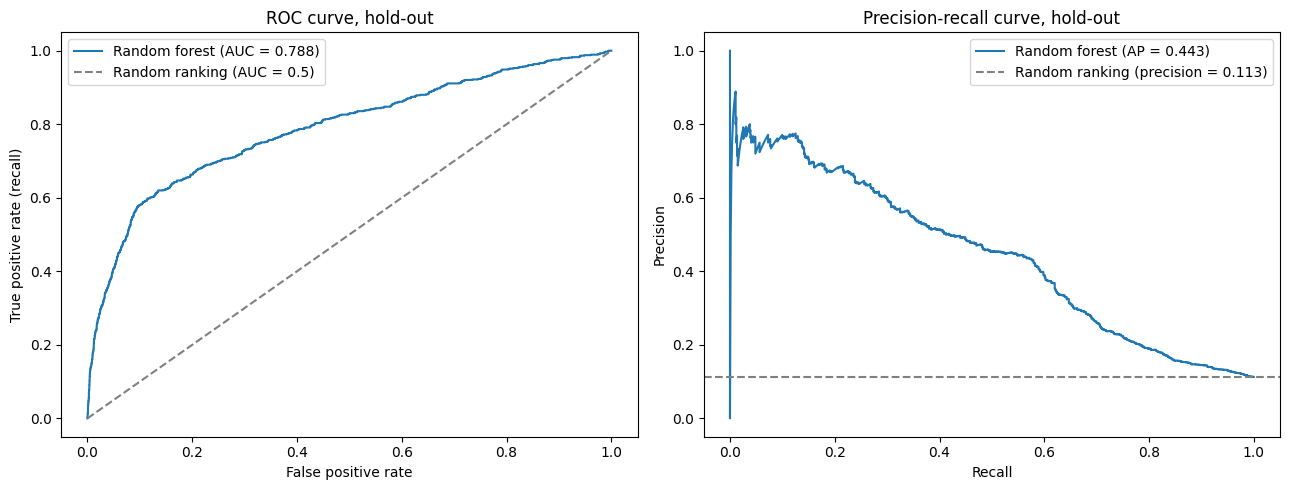

In [23]:
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix)

final_pipe = Pipeline([
    ("prep", make_preprocess()),
    ("model", RandomForestClassifier(n_estimators=300, max_features=0.3, min_samples_leaf=20,
                                     random_state=SEED)),
])
final_pipe.fit(X_dev, y_dev)
hold_score = final_pipe.predict_proba(X_hold)[:, 1]

hold_auc = roc_auc_score(y_hold, hold_score)
hold_ap = average_precision_score(y_hold, hold_score)
print(f"Hold-out ROC-AUC: {hold_auc:.4f}")
print(f"Hold-out AP     : {hold_ap:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fpr, tpr, _ = roc_curve(y_hold, hold_score)
axes[0].plot(fpr, tpr, label=f"Random forest (AUC = {hold_auc:.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Random ranking (AUC = 0.5)")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC curve, hold-out")
axes[0].legend()

prec, rec, _ = precision_recall_curve(y_hold, hold_score)
axes[1].plot(rec, prec, label=f"Random forest (AP = {hold_ap:.3f})")
axes[1].axhline(y_hold.mean(), linestyle="--", color="gray",
                label=f"Random ranking (precision = {y_hold.mean():.3f})")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curve, hold-out")
axes[1].legend()
plt.tight_layout()
plt.show()

In [24]:
n_call = int(round(0.10 * len(y_hold)))
cutoff = np.sort(hold_score)[::-1][n_call - 1]
hold_pred = (hold_score >= cutoff).astype(int)

tn, fp, fn, tp = confusion_matrix(y_hold, hold_pred).ravel()
called = tp + fp
precision_10 = tp / called
recall_10 = tp / (tp + fn)
base_rate = y_hold.mean()
lift_10 = precision_10 / base_rate

print(f"Hold-out size: {len(y_hold)}, yes in hold-out: {y_hold.sum()} ({base_rate:.4f})")
print(f"Capacity 10%: {n_call} calls, cutoff score = {cutoff:.4f}, actually called: {called}")
print(f"\nPrecision at top 10%: {precision_10:.4f}")
print(f"Recall at top 10%   : {recall_10:.4f}")
print(f"Lift over random    : {lift_10:.2f}x")
print(f"Random calling would find about {called * base_rate:.0f} yes out of {called} calls")

print("\nConfusion matrix (rows = real answer, columns = called or not):")
print(pd.DataFrame([[tn, fp], [fn, tp]],
                   index=["real no", "real yes"], columns=["not called", "called"]))

Hold-out size: 6588, yes in hold-out: 742 (0.1126)
Capacity 10%: 659 calls, cutoff score = 0.3499, actually called: 659

Precision at top 10%: 0.4947
Recall at top 10%   : 0.4394
Lift over random    : 4.39x
Random calling would find about 74 yes out of 659 calls

Confusion matrix (rows = real answer, columns = called or not):
          not called  called
real no         5513     333
real yes         416     326


### Results on the hold-out

On the hold-out the model gets ROC-AUC 0.788 and AP 0.443, lower than in CV (0.805 and 0.482). Part of it is that the CV score is a bit optimistic, because I picked the settings on the same folds, and part is that the hold-out is just one random sample. I trust the hold-out number more, and I don't change the model because of it, otherwise the hold-out would stop being a fair test.

10% rule: 10% of the hold-out is 659 clients, the score cutoff is 0.35. 326 of them say yes, so precision is 49.5% and recall is 43.9% (326 of 742 yes). Random calling would give about 74 yes, so the lift is 4.4x.

For the call-centre manager: if you call the top 659 clients from the model's list, about half of them (326) will open a deposit, compared to about 74 with random calls. The other 333 calls still end with a no, and 416 clients who would say yes don't get a call. Part of them would be missed anyway, because there are only 659 calls for 742 yes clients.

### Why these numbers are too optimistic

The split is random, but in real use the model is trained on the past and used on future calls. Here train and hold-out come from the same periods. The strongest features (nr.employed, euribor3m, emp.var.rate) basically mark the time period, so the model partly learns "in this period many people said yes" and gets checked on clients from the same periods. In a new campaign the period is new and this doesn't help, so in real use I'd expect lower AUC and lift.

## Stage 8. Final model, saving and predictions

I refit the same pipeline (same settings) on all of train.csv, the dev part plus the hold-out, so the final model sees as much data as possible. Then I save it with joblib and score test.csv. For y_pred I use the same 10% rule as on the hold-out: the top 10% of the test list by score get a call (1), the rest get 0.

In [25]:
from sklearn.base import clone

model_full = clone(final_pipe)
model_full.fit(X, y)

joblib.dump(model_full, "model.joblib", compress=3)
print(f"model.joblib: {os.path.getsize('model.joblib') / 1e6:.1f} MB")

model.joblib: 9.4 MB


In [26]:
X_test = test.drop(columns=["id"])
test_score = model_full.predict_proba(X_test)[:, 1]

n_call_test = int(round(0.10 * len(test)))
order = np.argsort(-test_score, kind="stable")
test_pred = np.zeros(len(test), dtype=int)
test_pred[order[:n_call_test]] = 1

predictions = pd.DataFrame({"id": test["id"], "y_pred": test_pred, "y_score": test_score})
predictions.to_csv("predictions.csv", index=False)

print(predictions.head())
print(f"\nrows: {len(predictions)} (test has {len(test)})")
print(f"all ids present and unique: {set(predictions['id']) == set(test['id']) and predictions['id'].is_unique}")
print(f"y_pred = 1: {predictions['y_pred'].sum()} ({predictions['y_pred'].mean():.4f})")
print(f"lowest score among called: {test_score[test_pred == 1].min():.4f}")

      id  y_pred   y_score
0  32940       0  0.029366
1  32941       0  0.036065
2  32942       0  0.048123
3  32943       0  0.080388
4  32944       0  0.039487

rows: 8236 (test has 8236)
all ids present and unique: True
y_pred = 1: 824 (0.1000)
lowest score among called: 0.3305


model.joblib is 9.4 MB. I checked it in a fresh Python process started in the repository root: it loads with joblib.load, scores the raw test.csv columns (without id) with no extra steps, and its scores match y_score in predictions.csv (max difference 1e-16). 824 clients (10%) have y_pred = 1.

## Summary

Final model: random forest (300 trees, max_features 0.3, min_samples_leaf 20) inside one sklearn pipeline. CV on the dev part: AP 0.482, ROC-AUC 0.805. Hold-out: AP 0.443, ROC-AUC 0.788, and with the 10% rule precision 49.5%, recall 43.9%, lift 4.4x. The model is saved as model.joblib, predictions for test.csv are in predictions.csv, and the model card is in REPORT.md.